In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (OneHotEncoder, StandardScaler)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

df=pd.read_csv("C:\\customer-intelligence\\data\\processed\\cleaned_customer_data.csv")
print(df.shape)

(7043, 21)


In [2]:
df=df.drop(columns=["customerID"])
X=df.drop(columns=["Churn"])
y=df["Churn"].map({"Yes":1, "No":0})

print("Features:",X.shape)
print("Target:",y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features: (7043, 19)
Target: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [3]:
numerical_features=X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorial_features=X.select_dtypes(include=["object","str","category"]).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorial_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [5]:
encoder=OneHotEncoder(handle_unknown="ignore")

scaler=StandardScaler()

In [6]:
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorial_features)
    ]
)

In [7]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training records:",X_train.shape[0])
print("Testing records:",X_test.shape[0])

Training records: 5634
Testing records: 1409


In [8]:
print("Training churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training churn distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [9]:
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline

logistic_model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(max_iter=1000,random_state=42))
    ]
)
logistic_model.fit(X_train,y_train)
print("model Training completed")

model Training completed


In [12]:
y_pred=logistic_model.predict(X_test)
y_prob=logistic_model.predict_proba(X_test)[:,1]

print("Prediction:  ",y_pred[:10])
print("Probability: ",y_prob[:10])

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Prediction:   [0 1 0 0 0 1 0 0 0 0]
Probability:  [0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]
Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664
ROC-AUC: 0.8421349040274871

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



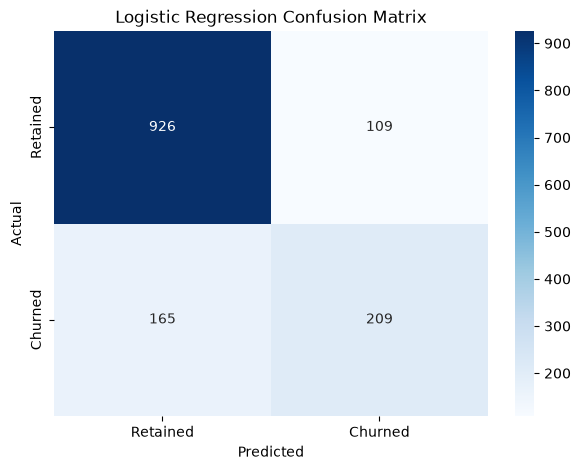

[[926 109]
 [165 209]]


In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Retained", "Churned"],
    yticklabels=["Retained", "Churned"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

print(cm)

In [14]:
from sklearn.metrics import (
    precision_recall_curve,
    PrecisionRecallDisplay
)
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)
validation_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

validation_model.fit(X_train_sub, y_train_sub)

val_prob = validation_model.predict_proba(X_val)[:, 1]


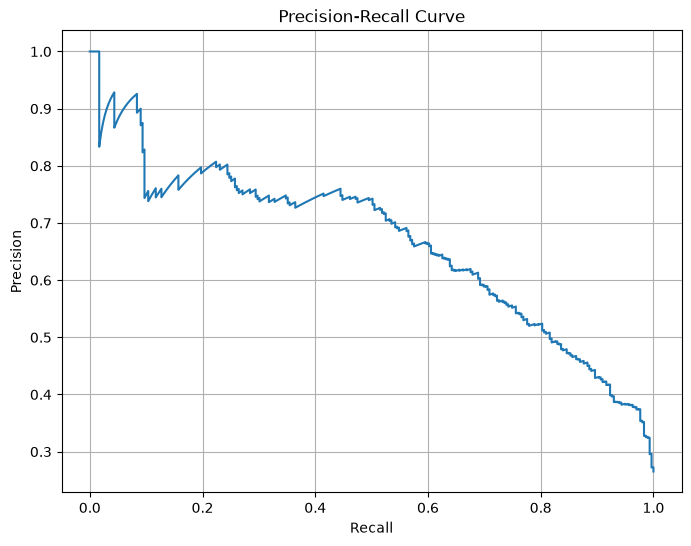

In [15]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob
)

plt.figure(figsize=(8, 6))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.grid()
plt.show()

In [16]:
target_recall = 0.70

valid_indices = np.where(
    recall[:-1] >= target_recall
)[0]

if len(valid_indices) > 0:
    best_idx = valid_indices[
        np.argmax(precision[:-1][valid_indices])
    ]

    best_threshold = thresholds[best_idx]

    print("Selected threshold:", best_threshold)
    print("Validation precision:", precision[best_idx])
    print("Validation recall:", recall[best_idx])
else:
    print("Target recall not achieved.")

Selected threshold: 0.3645330664773289
Validation precision: 0.5898876404494382
Validation recall: 0.7023411371237458


In [17]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Use the original model trained on full training data
optimized_threshold = best_threshold

# Apply optimized threshold to test probabilities
y_pred_optimized = (
    y_prob >= optimized_threshold
).astype(int)

print("Optimized Threshold:", optimized_threshold)

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_optimized))

print("Precision:",
      precision_score(y_test, y_pred_optimized))

print("Recall:",
      recall_score(y_test, y_pred_optimized))

print("F1 Score:",
      f1_score(y_test, y_pred_optimized))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_optimized))

Optimized Threshold: 0.3645330664773289

Accuracy: 0.7693399574166075
Precision: 0.5515789473684211
Recall: 0.7005347593582888
F1 Score: 0.6171967020023557
ROC-AUC: 0.8421349040274871

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.79      0.83      1035
           1       0.55      0.70      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409



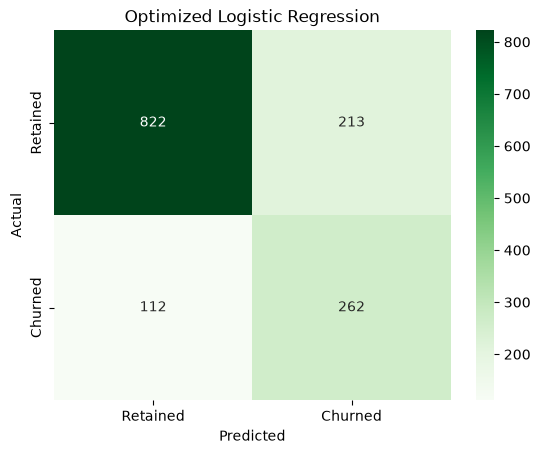

In [18]:
cm_optimized = confusion_matrix(
    y_test,
    y_pred_optimized
)

sns.heatmap(
    cm_optimized,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Retained", "Churned"],
    yticklabels=["Retained", "Churned"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Optimized Logistic Regression")
plt.show()